# 09_13 The Bias-Variance Trade-off

**Learning objectives**
- Derive the decomposition **expected test error = noise + bias$^2$ + variance** and measure each term by simulation (many training sets drawn from the same population).
- See how **model complexity** (polynomial degree, $k$ of nearest neighbours, ridge penalty) moves bias and variance in opposite directions, and how the **sample size** shifts the optimum.
- Use **bagging** to reduce variance, and read **cross-validation** as an estimate of the expected test error.
- Recognise the limits of the classical U-shape: the **interpolation threshold and double descent** of over-parameterised models.

**Prerequisites:** [05_01 Law of large numbers](../../module_05_sampling/notebooks/05_01_law_of_large_numbers.ipynb), [05_04 Bootstrap](../../module_05_sampling/notebooks/05_04_bootstrap.ipynb), [09_12 Priors as regularisers](09_12_priors_as_regularisers.ipynb), [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
For a random variable $Z$: $E[(Z-c)^2]=\mathrm{Var}(Z)+(E Z-c)^2$ for any constant $c$. A fitted model $\hat f$ depends on the random training sample, so $\hat f(x)$ is a random variable at each fixed $x$. The bootstrap (05_04) mimics drawing new training sets by resampling the one we have.

## 3. Intuition and story
You are asked to predict next month's sales from 30 past months. A **straight line** is stable: refit it on any other 30 months and it hardly changes, but it cannot follow the seasonal curve, so it is systematically wrong (**bias**). A **degree-15 polynomial** can follow any curve, but through 30 noisy points it wiggles to hit each of them, and on another 30 months it would wiggle completely differently (**variance**). The prediction error has three sources: the noise nobody can predict, the systematic miss of a model too simple for the truth, and the instability of a model too flexible for the data. You pay for each, and the best model balances the last two.

## 4. Formal definitions

Data $y=f(x)+\varepsilon$, $E\varepsilon=0$, $\mathrm{Var}\,\varepsilon=\sigma^2$. A learning algorithm maps a training set $\mathcal D$ to $\hat f_{\mathcal D}$. At a fixed test input $x$, with the expectation over training sets $\mathcal D$ and over the noise in the new response $y=f(x)+\varepsilon$:

$$E\big[(y-\hat f_{\mathcal D}(x))^2\big]=\underbrace{\sigma^2}_{\text{irreducible noise}}+\underbrace{\big(E_{\mathcal D}\hat f(x)-f(x)\big)^2}_{\text{bias}^2}+\underbrace{\mathrm{Var}_{\mathcal D}\big(\hat f(x)\big)}_{\text{variance}}.$$

| Model family | Complexity knob | Bias | Variance |
|---|---|---|---|
| Polynomial of degree $d$ | $d$ | falls with $d$ | rises with $d$ ($\approx\sigma^2(d+1)/n$ on average) |
| $k$-nearest neighbours | $k$ | rises with $k$ | falls with $k$ ($\approx\sigma^2/k$) |
| Ridge | $\lambda$ | rises with $\lambda$ | falls with $\lambda$ |

**Training error** is optimistic; the **expected test error** is the sum above. $K$-fold cross-validation estimates it from the data. **Bagging:** average $B$ models fitted on bootstrap resamples.

## 5. Derivations

### 5.1 The decomposition
Write $\bar f(x)=E_{\mathcal D}\hat f(x)$. Then $y-\hat f=(y-f)+(f-\bar f)+(\bar f-\hat f)$ where the three terms are, respectively, the noise (mean zero, independent of $\hat f$), a constant (the bias) and a mean-zero fluctuation of the estimator. Squaring and taking expectations, all cross-terms vanish: the noise is independent of everything else and $E[\bar f-\hat f]=0$. What remains is $\sigma^2+(f-\bar f)^2+E(\bar f-\hat f)^2$. **In plain words.** The error is the sum of three non-negative parts that do not interact: what nobody can know, what the model gets wrong on average, and how much the model changes from sample to sample.

### 5.2 Variance of a linear smoother
If $\hat f(x_0)=\sum_iw_i(x_0)y_i$ with fixed weights, then $\mathrm{Var}\,\hat f(x_0)=\sigma^2\sum_iw_i^2$. For $k$-NN, $w_i=1/k$ on the $k$ nearest points: variance $\sigma^2/k$. For least squares with $d+1$ parameters the average over the sample points of the variance is $\sigma^2(d+1)/n$ (trace of the hat matrix over $n$). **In plain words.** Averaging $k$ noisy values divides the variance by $k$; fitting $d+1$ parameters to $n$ points costs a fraction $(d+1)/n$ of the noise variance.

### 5.3 Bias of a smoother
$\mathrm{bias}\,\hat f(x_0)=\sum_iw_i(x_0)f(x_i)-f(x_0)$: for $k$-NN it is the average of $f$ over the neighbourhood minus $f(x_0)$, about $\frac{f''}{2}\cdot(\text{neighbourhood width})^2/12$ in 1D, growing with $k/n$. **In plain words.** A smoother that averages over a wider window blurs the peaks of the true function: that blur is the bias.

### 5.4 The optimum moves with $n$
Variance terms scale like $1/n$ (for a fixed model) while bias is a property of the model class, not of $n$. With more data the variance penalty of flexible models falls, so the best complexity grows with $n$ (the optimal $k$ of $k$-NN grows like $n^{4/5}$ in 1D, the optimal degree grows slowly with $n$). **In plain words.** With little data use a simple model; with a lot of data you can afford a complex one.

### 5.5 Bagging reduces variance
For $B$ estimators with variance $v$ and pairwise correlation $\rho$ the average has variance $\rho v+\frac{1-\rho}{B}v$; bootstrap models are positively correlated ($\rho<1$), so bagging cuts the variance towards $\rho v$ and leaves the bias roughly unchanged. **In plain words.** Averaging many different wiggly fits cancels the wiggles that are due to the particular sample, but not the systematic error.

### 5.6 Beyond the U: interpolation and double descent
When the number of parameters $p$ grows past the number of observations $n$ a least-squares model can interpolate the data; the minimum-norm interpolator has a test error that **peaks at $p\approx n$** (the design matrix is nearly singular, variance explodes) and **decreases again for $p\gg n$** because the minimum-norm solution is an implicit regulariser. **In plain words.** The classical picture (a single U) describes models with fewer parameters than data; very large models can be better again, as long as the fit is the smoothest one that interpolates.

## 6. Properties and relationships
- **Bias and variance are properties of the algorithm *and* of the population**, estimated here by repeated sampling, impossible with one real dataset; cross-validation and the bootstrap are the practical substitutes.
- **The decomposition is for squared error**; for 0-1 loss and other losses the decomposition is less clean (but the idea persists).
- **Regularisation** trades variance for bias (09_12); **ensembles** reduce variance (bagging, random forests); **boosting** reduces bias.
- **Training error always falls with complexity,** so it cannot select the model; the test error is U-shaped (classical regime).
- **Irreducible error** $\sigma^2$ is a floor: no model beats it, and a model that approaches it is not worth more complexity.
- **Link to ML and AI:** model selection and hyper-parameter tuning, learning curves (diagnose high bias vs high variance), random forests and gradient boosting, ensembles of neural networks (09_06), scaling laws and double descent in deep learning, the choice of $k$ in nearest-neighbour search and of the context size in kernel methods.

## 7. Machinery: polynomial fits, nearest neighbours and a bias-variance estimator

The true function is $f(x)=\sin 2\pi x$ on $[0,1]$ and the noise SD is $\sigma=0.3$. The inputs are fixed on an equally spaced grid (a fixed design); the estimator draws $R$ independent noise realisations, i.e. $R$ training sets of size $n$, fits a model to each, and evaluates the predictions on a fixed test grid.

In [2]:
f_true = lambda x: np.sin(2 * np.pi * x); SIG = 0.3; xt_grid = np.linspace(0.02, 0.98, 97); ft = f_true(xt_grid)
def poly_fit_pred(x, y, deg, xs): return np.polynomial.polynomial.polyval(2 * xs - 1, np.polynomial.polynomial.polyfit(2 * x - 1, y, deg))
def knn_pred(x, y, k, xs): d = np.abs(xs[:, None] - x[None, :]); idx = np.argsort(d, axis=1)[:, :k]; return y[idx].mean(axis=1)
def tree_pred(x, y, xs, depth=4, minleaf=3):
    o = np.argsort(x); x = x[o]; y = y[o]; out = np.zeros(len(xs)); cs = np.r_[0, np.cumsum(y)]; cs2 = np.r_[0, np.cumsum(y ** 2)]
    def sse(a, b): m = b - a; s1 = cs[b] - cs[a]; return (cs2[b] - cs2[a]) - s1 ** 2 / m
    def node(i0, i1, d, mask):
        if d == 0 or i1 - i0 < 2 * minleaf: out[mask] = y[i0:i1].mean(); return
        best = None
        for sp in range(i0 + minleaf, i1 - minleaf + 1):
            v = sse(i0, sp) + sse(sp, i1)
            if best is None or v < best[0]: best = (v, sp)
        sp = best[1]; thr = 0.5 * (x[sp - 1] + x[sp]); node(i0, sp, d - 1, mask & (xs <= thr)); node(sp, i1, d - 1, mask & (xs > thr))
    node(0, len(x), depth, np.ones(len(xs), bool)); return out
def bv(predict, n, R=400, seed=0, ridge_noise=False):
    g = np.random.default_rng(seed); P = np.zeros((R, len(xt_grid))); tr_err = np.zeros(R)
    for r in range(R):
        x = (np.arange(n) + 0.5) / n; y = f_true(x) + SIG * g.normal(size=n); P[r] = predict(x, y, xt_grid); tr_err[r] = np.mean((predict(x, y, x) - y) ** 2)
    mean = P.mean(axis=0); bias2 = np.mean((mean - ft) ** 2); var = P.var(axis=0, ddof=1).mean(); test = SIG ** 2 + bias2 + var; return dict(bias2=bias2, variance=var, noise=SIG ** 2, expected_test_error=test, train_error=tr_err.mean(), P=P)
r3 = bv(lambda x, y, xs: poly_fit_pred(x, y, 3, xs), 30); g = np.random.default_rng(99); direct = np.mean([np.mean((poly_fit_pred(*(lambda x: (x, f_true(x) + SIG * g.normal(size=30)))((np.arange(30) + 0.5) / 30), 3, xt_grid) - (ft + SIG * g.normal(size=97))) ** 2) for _ in range(3000)])
print(f"degree 3, n = 30: bias^2 {r3['bias2']:.4f}, variance {r3['variance']:.4f}, noise {SIG ** 2:.4f}, sum {r3['expected_test_error']:.4f} | direct simulation of the expected test error (3,000 fresh training sets and fresh noisy test points) {direct:.4f} | training error {r3['train_error']:.4f}")
assert abs(direct - r3["expected_test_error"]) < 0.01 and r3["train_error"] < r3["expected_test_error"]

degree 3, n = 30: bias^2 0.0036, variance 0.0112, noise 0.0900, sum 0.1048 | direct simulation of the expected test error (3,000 fresh training sets and fresh noisy test points) 0.1049 | training error 0.0818


## 8. 2D visuals

### 8.1 Spaghetti plots: many fits from many training sets
For four degrees (1, 3, 6, 12) the fits to 40 different training sets of $n=30$ points (grey) with the true function (red) and the average fit (blue). The degree-1 fits are all alike but all wrong (high bias, low variance); the degree-12 fits scatter wildly around the truth (low bias, high variance).

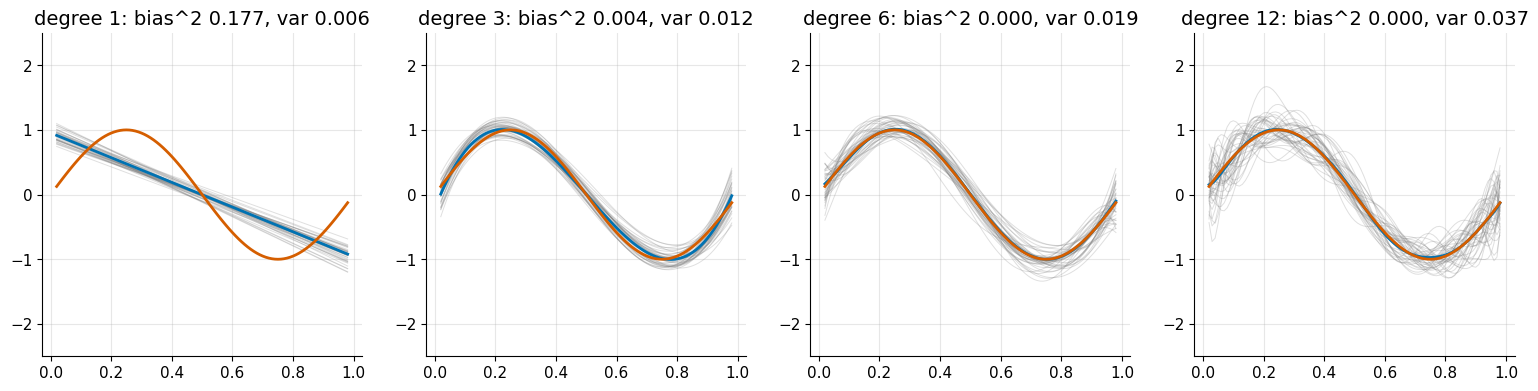

{1: (np.float64(0.1772), np.float64(0.0059)), 3: (np.float64(0.0036), np.float64(0.0115)), 6: (np.float64(0.0001), np.float64(0.0185)), 12: (np.float64(0.0002), np.float64(0.0374))}


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2)); res8 = {}
for ax, deg in zip(axes, (1, 3, 6, 12)):
    r_ = bv(lambda x, y, xs, d=deg: poly_fit_pred(x, y, d, xs), 30, R=200, seed=deg); res8[deg] = r_
    for row in r_["P"][:40]: ax.plot(xt_grid, np.clip(row, -3, 3), color="gray", alpha=0.25, linewidth=0.7)
    ax.plot(xt_grid, np.clip(r_["P"].mean(axis=0), -3, 3), color=MAIN, linewidth=2); ax.plot(xt_grid, ft, color=HIGHLIGHT, linewidth=2); ax.set_ylim(-2.5, 2.5); ax.set_title(f"degree {deg}: bias^2 {r_['bias2']:.3f}, var {r_['variance']:.3f}")
plt.show(); print({d: (round(r_["bias2"], 4), round(r_["variance"], 4)) for d, r_ in res8.items()}); assert res8[1]["bias2"] > res8[3]["bias2"] > res8[12]["bias2"] and res8[1]["variance"] < res8[6]["variance"] < res8[12]["variance"]

### 8.2 The U-shaped test error
For polynomial degrees 0 to 14 ($n=30$): training error, expected test error and its decomposition. The training error keeps falling; the test error is U-shaped; the bias$^2$ falls and the variance rises with the degree.

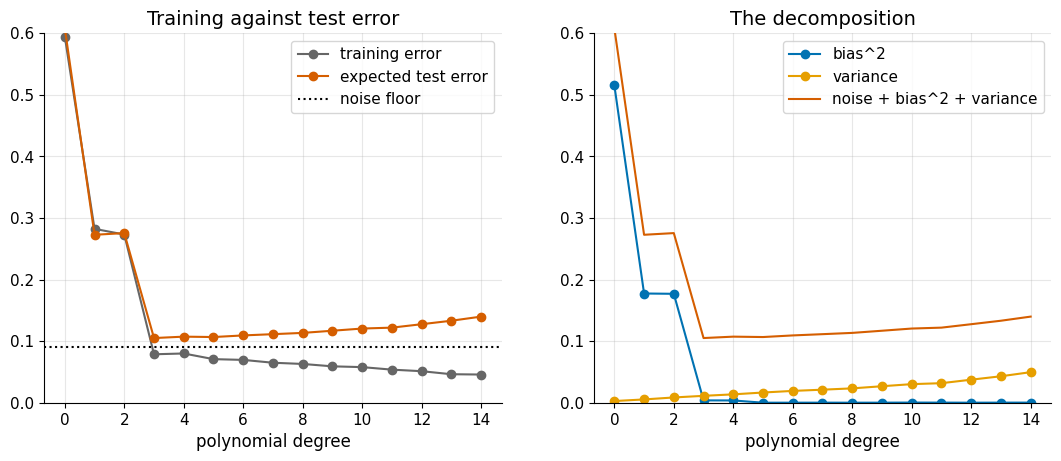

best degree 3: expected test error 0.1050 (noise floor 0.0900); degree 1: 0.273, degree 14: 0.140


In [4]:
degs = np.arange(0, 15); out = {d: bv(lambda x, y, xs, d=d: poly_fit_pred(x, y, d, xs), 30, R=300, seed=100 + d) for d in degs}; tab = pd.DataFrame({d: {k: v for k, v in o.items() if k != "P"} for d, o in out.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].plot(degs, tab["train_error"], "o-", color=NEUTRAL, label="training error"); axes[0].plot(degs, tab["expected_test_error"], "o-", color=HIGHLIGHT, label="expected test error"); axes[0].axhline(SIG ** 2, color="black", linestyle=":", label="noise floor"); axes[0].set_ylim(0, 0.6); axes[0].legend(); axes[0].set_xlabel("polynomial degree"); axes[0].set_title("Training against test error")
axes[1].plot(degs, tab["bias2"], "o-", color=MAIN, label="bias^2"); axes[1].plot(degs, tab["variance"], "o-", color=SIM, label="variance"); axes[1].plot(degs, SIG ** 2 + tab["bias2"] + tab["variance"], color=HIGHLIGHT, label="noise + bias^2 + variance"); axes[1].set_ylim(0, 0.6); axes[1].legend(); axes[1].set_xlabel("polynomial degree"); axes[1].set_title("The decomposition")
plt.show(); best = int(tab["expected_test_error"].idxmin()); print(f"best degree {best}: expected test error {tab['expected_test_error'].min():.4f} (noise floor {SIG ** 2:.4f}); degree 1: {tab.loc[1, 'expected_test_error']:.3f}, degree 14: {tab.loc[14, 'expected_test_error']:.3f}"); assert tab["train_error"].is_monotonic_decreasing or (tab["train_error"].diff().dropna() < 0.002).all(); assert 3 <= best <= 7 and tab.loc[14, "variance"] > 3 * tab.loc[3, "variance"]

### 8.3 Cross-validation estimates the expected test error
For one training set of $n=30$ points, the leave-one-out CV error of each degree (closed form from the hat matrix) against the true expected test error of 8.2 and a large independent test set.

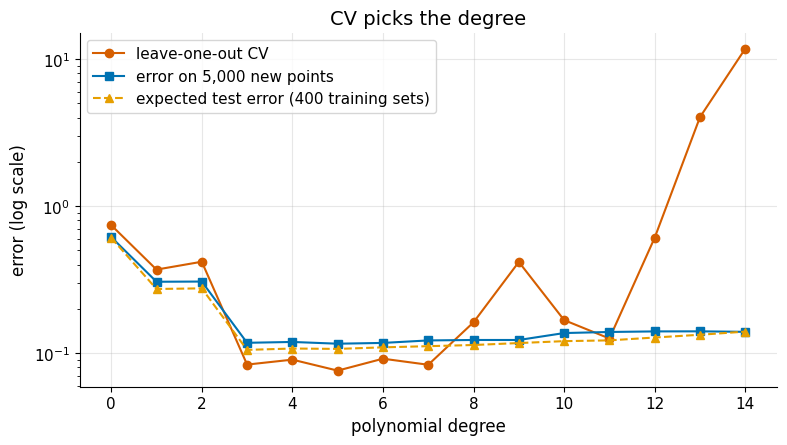

degree chosen by leave-one-out CV: 5 | by the large test set: 5 | by the expected test error: 3


In [5]:
g = np.random.default_rng(7); xs1 = (np.arange(30) + 0.5) / 30; ys1 = f_true(xs1) + SIG * g.normal(size=30); xte = g.uniform(0, 1, 5000); yte = f_true(xte) + SIG * g.normal(size=5000); loo = []; tst = []
for d in degs:
    A = np.polynomial.polynomial.polyvander(2 * xs1 - 1, d); H = A @ np.linalg.pinv(A); res = ys1 - H @ ys1; loo.append(np.mean((res / (1 - np.diag(H))) ** 2)); tst.append(np.mean((poly_fit_pred(xs1, ys1, d, xte) - yte) ** 2))
loo = np.array(loo); tst = np.array(tst); fig, ax = plt.subplots(figsize=(9, 4.6)); ax.semilogy(degs, loo, "o-", color=HIGHLIGHT, label="leave-one-out CV"); ax.semilogy(degs, tst, "s-", color=MAIN, label="error on 5,000 new points"); ax.semilogy(degs, tab["expected_test_error"], "^--", color=SIM, label="expected test error (400 training sets)"); ax.legend(); ax.set_xlabel("polynomial degree"); ax.set_ylabel("error (log scale)"); ax.set_title("CV picks the degree")
plt.show(); print("degree chosen by leave-one-out CV:", int(degs[np.argmin(loo)]), "| by the large test set:", int(degs[np.argmin(tst)]), "| by the expected test error:", best); assert abs(int(degs[np.argmin(loo)]) - int(degs[np.argmin(tst)])) <= 2

## 9. 3D visuals

### 9.1 Static: the expected test error over (degree, sample size)
More data lower the whole surface and move the best degree to the right: a cubic is best up to $n=50$ and a degree-5 polynomial from $n=100$ on.

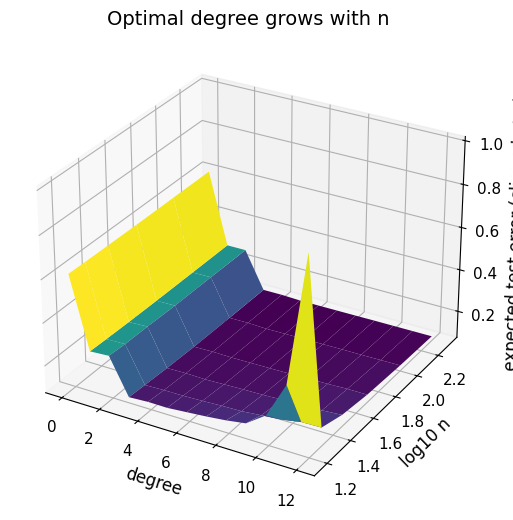

best degree by n: {15: 3, 20: 3, 30: 3, 50: 3, 100: 5, 200: 5} | minimal error by n: {15: 0.117, 20: 0.112, 30: 0.105, 50: 0.1, 100: 0.094, 200: 0.093}


In [6]:
ns_ = np.array([15, 20, 30, 50, 100, 200]); dg = np.arange(0, 13); E = np.zeros((len(ns_), len(dg))); B2 = np.zeros_like(E); V = np.zeros_like(E)
for i, n_ in enumerate(ns_):
    for j, d in enumerate(dg): o = bv(lambda x, y, xs, d=d: poly_fit_pred(x, y, d, xs), n_, R=120, seed=1000 + 17 * i + j); E[i, j] = o["expected_test_error"]; B2[i, j] = o["bias2"]; V[i, j] = o["variance"]
DD, NN = np.meshgrid(dg, np.log10(ns_)); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(DD, NN, np.minimum(E, 1.0), cmap="viridis", edgecolor="none"); ax.set_xlabel("degree"); ax.set_ylabel("log10 n"); ax.set_zlabel("expected test error (clipped at 1)"); ax.set_title("Optimal degree grows with n"); ax.view_init(elev=28, azim=-60)
plt.show(); bd = dg[np.argmin(E, axis=1)]; print("best degree by n:", dict(zip(ns_.tolist(), bd.tolist())), "| minimal error by n:", dict(zip(ns_.tolist(), E.min(axis=1).round(3).tolist()))); assert bd[-1] > bd[0] and E.min(axis=1)[-1] < E.min(axis=1)[0]

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=dg, y=np.log10(ns_), z=np.minimum(E, 1.0), colorscale="Viridis")); fig.update_layout(title="Expected test error", width=760, height=560, scene=dict(xaxis_title="degree", yaxis_title="log10 n", zaxis_title="error")); fig.show()

### 9.3 Static: bias$^2$ and variance as two surfaces
The same grid split into squared bias (falls with the degree, almost independent of $n$) and variance (rises with the degree, falls with $n$).

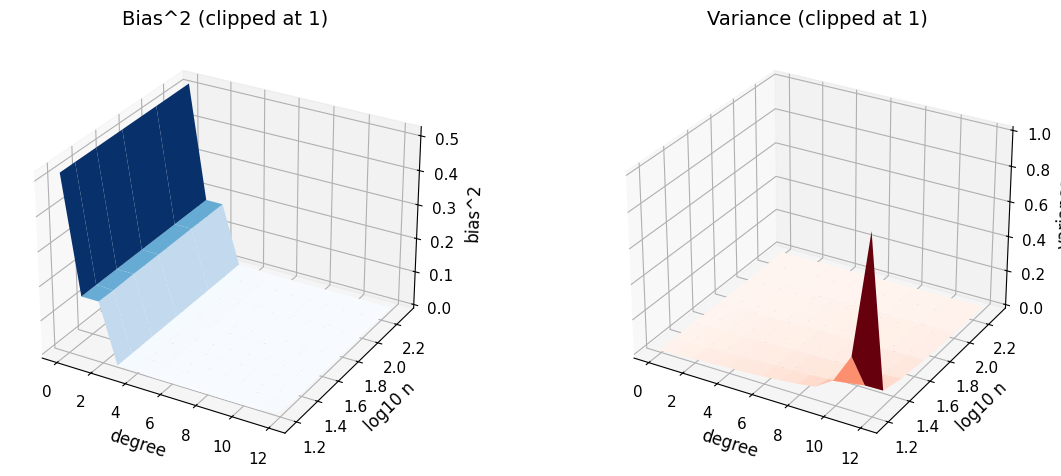

degree 6: bias^2 by n: [0.0004, 0.0002, 0.0002, 0.0001, 0.0001, 0.0] | variance by n: [0.039, 0.0286, 0.0181, 0.0111, 0.0057, 0.0027] | n x variance: [0.59, 0.57, 0.54, 0.55, 0.57, 0.53]


In [8]:
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(DD, NN, np.minimum(B2, 1.0), cmap="Blues", edgecolor="none"); ax.set_xlabel("degree"); ax.set_ylabel("log10 n"); ax.set_zlabel("bias^2"); ax.set_title("Bias^2 (clipped at 1)"); ax.view_init(elev=28, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(DD, NN, np.minimum(V, 1.0), cmap="Reds", edgecolor="none"); ax.set_xlabel("degree"); ax.set_ylabel("log10 n"); ax.set_zlabel("variance"); ax.set_title("Variance (clipped at 1)"); ax.view_init(elev=28, azim=-60)
plt.show(); j = list(dg).index(6); print("degree 6: bias^2 by n:", B2[:, j].round(4).tolist(), "| variance by n:", V[:, j].round(4).tolist(), "| n x variance:", (V[:, j] * ns_).round(2).tolist()); assert V[0, j] > 5 * V[-1, j] and B2[0, j] < 3 * B2[-1, j] + 0.05

## 10. Simulation vs theory

### 10.1 Variance of least squares: $\sigma^2(d+1)/n$
Average the pointwise variance over the training inputs: for fixed design points the theory is exact; for random design it is a good approximation. Check it for degrees 1 to 6 and $n=40$ with *fixed* inputs.

In [9]:
g = np.random.default_rng(5); n = 40; xs = np.linspace(0.02, 0.98, n); rows = []
for d in range(1, 7):
    A = np.polynomial.polynomial.polyvander(2 * xs - 1, d); H = A @ np.linalg.pinv(A); fits = np.array([H @ (f_true(xs) + SIG * g.normal(size=n)) for _ in range(20_000)]); rows.append((d, fits.var(axis=0, ddof=1).mean(), SIG ** 2 * (d + 1) / n, np.trace(H)))
tb = pd.DataFrame(rows, columns=["degree", "mean variance at the design points (sim)", "sigma^2 (d + 1) / n", "trace of the hat matrix"]); print(tb.round(5).to_string(index=False)); assert all(abs(r[1] / r[2] - 1) < 0.03 for r in rows) and all(abs(r[3] - (r[0] + 1)) < 1e-9 for r in rows)

 degree  mean variance at the design points (sim)  sigma^2 (d + 1) / n  trace of the hat matrix
      1                                   0.00449              0.00450                      2.0
      2                                   0.00677              0.00675                      3.0
      3                                   0.00903              0.00900                      4.0
      4                                   0.01129              0.01125                      5.0
      5                                   0.01355              0.01350                      6.0
      6                                   0.01597              0.01575                      7.0


### 10.2 Variance of $k$-NN: $\sigma^2/k$ (and the bias of the window)
For $k$-nearest-neighbour regression at interior test points the variance is $\sigma^2/k$ exactly for fixed neighbours; with random inputs it is close. We also check how the bias$^2$ grows with $k$.

In [10]:
rows = []; n = 100
for k in (1, 3, 5, 10, 20, 40):
    o = bv(lambda x, y, xs, k=k: knn_pred(x, y, k, xs), n, R=400, seed=300 + k); rows.append((k, o["variance"], SIG ** 2 / k, o["bias2"], o["expected_test_error"]))
tb = pd.DataFrame(rows, columns=["k", "variance (sim)", "sigma^2 / k", "bias^2", "expected test error"]); print(tb.round(4).to_string(index=False)); assert all(abs(r[1] / r[2] - 1) < 0.15 for r in rows) and tb["bias^2"].iloc[-1] > 20 * tb["bias^2"].iloc[1] and (tb["bias^2"].diff().dropna().iloc[2:] > 0).all()

 k  variance (sim)  sigma^2 / k  bias^2  expected test error
 1          0.0893       0.0900  0.0007               0.1800
 3          0.0298       0.0300  0.0006               0.1204
 5          0.0179       0.0180  0.0006               0.1086
10          0.0090       0.0090  0.0012               0.1001
20          0.0045       0.0045  0.0125               0.1070
40          0.0022       0.0022  0.0523               0.1445


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("decomposition by simulation: P = predictions from R training sets; bias2 = mean((P.mean(0) - f)**2); variance = P.var(0, ddof=1).mean(); test error = sigma**2 + bias2 + variance")
print("polynomial fit: np.polynomial.polynomial.polyfit(x, y, deg) / polyval | hat matrix: H = A @ np.linalg.pinv(A); LOO residual = (y - H y) / (1 - diag(H)) | trace(H) = number of parameters")
print("library equivalents: sklearn.model_selection.cross_val_score, learning_curve, validation_curve; sklearn.ensemble.BaggingRegressor, RandomForestRegressor")
Hh = np.polynomial.polynomial.polyvander(np.linspace(0, 1, 12), 3); Hm = Hh @ np.linalg.pinv(Hh); yy = f_true(np.linspace(0, 1, 12)); res = yy - Hm @ yy; loo_f = res / (1 - np.diag(Hm)); loo_e = [yy[i] - np.polynomial.polynomial.polyval(np.linspace(0, 1, 12)[i], np.polynomial.polynomial.polyfit(np.delete(np.linspace(0, 1, 12), i), np.delete(yy, i), 3)) for i in range(12)]
print("closed-form leave-one-out residuals vs explicit refits (max abs difference):", np.abs(loo_f - np.array(loo_e)).max())
assert np.abs(loo_f - np.array(loo_e)).max() < 1e-9

decomposition by simulation: P = predictions from R training sets; bias2 = mean((P.mean(0) - f)**2); variance = P.var(0, ddof=1).mean(); test error = sigma**2 + bias2 + variance
polynomial fit: np.polynomial.polynomial.polyfit(x, y, deg) / polyval | hat matrix: H = A @ np.linalg.pinv(A); LOO residual = (y - H y) / (1 - diag(H)) | trace(H) = number of parameters
library equivalents: sklearn.model_selection.cross_val_score, learning_curve, validation_curve; sklearn.ensemble.BaggingRegressor, RandomForestRegressor
closed-form leave-one-out residuals vs explicit refits (max abs difference): 1.2212453270876722e-14


## 12. Real-world worked examples

---
### Example 1 (main): choosing the degree of a seasonal trend

**Scenario.** Monthly demand follows a smooth seasonal curve plus noise: $y=\sin2\pi x+\varepsilon$ with noise SD 0.3, observed at equally spaced times $x\in[0,1]$. We have $n=30$ observations and fit polynomials of degree 0 to 14.

**Questions**
1. For each degree, what are the squared bias, the variance, the training error and the expected test error (400 training sets)? Which degree is best?
2. Which degree is selected by leave-one-out cross-validation on a *single* dataset, and how variable is that choice over 200 datasets?
3. How much worse is the degree-14 fit than the best one, and how much of that is variance?

### 12.1 By hand
For a degree-$d$ polynomial the average variance is $\sigma^2(d+1)/n=0.09(d+1)/30$: $0.012$ for $d=3$, $0.042$ for $d=13$ and $0.045$ for $d=14$ (a fixed-design formula; for random inputs the variance near the ends of the interval is much larger). The bias of a cubic fit to $\sin2\pi x$ on $[0,1]$ is small but not zero; a straight line misses the oscillation completely (bias$^2$ about 0.2). The best degree balances them: we expect a low degree (3 to 5) and a test error close to the noise 0.09 plus a few thousandths to hundredths.

In [12]:
print(tab.round(4).to_string()); print(f"Q1: best degree {best}; error at the best {tab['expected_test_error'].min():.4f} = noise {SIG ** 2:.4f} + bias^2 {tab.loc[best, 'bias2']:.4f} + variance {tab.loc[best, 'variance']:.4f}")
g = np.random.default_rng(21); picks = []
for r in range(200):
    xs_ = (np.arange(30) + 0.5) / 30; ys_ = f_true(xs_) + SIG * g.normal(size=30); lo = []
    for d in degs:
        A = np.polynomial.polynomial.polyvander(2 * xs_ - 1, d); Hh = A @ np.linalg.pinv(A); lo.append(np.mean(((ys_ - Hh @ ys_) / (1 - np.clip(np.diag(Hh), 0, 0.999))) ** 2))
    picks.append(int(degs[np.argmin(lo)]))
picks = np.array(picks); print(f"Q2: degree chosen by leave-one-out CV over 200 datasets: median {np.median(picks):.0f}, 10th-90th percentile {np.quantile(picks, 0.1):.0f} to {np.quantile(picks, 0.9):.0f}; share within 2 of the best degree {np.mean(np.abs(picks - best) <= 2):.2f}")
print(f"Q3: degree 14: expected test error {tab.loc[14, 'expected_test_error']:.3f} = noise {SIG ** 2:.3f} + bias^2 {tab.loc[14, 'bias2']:.4f} + variance {tab.loc[14, 'variance']:.3f}; excess over the best {tab.loc[14, 'expected_test_error'] - tab['expected_test_error'].min():.3f}, of which variance {tab.loc[14, 'variance'] - tab.loc[best, 'variance']:.3f}")

     bias2  variance  noise  expected_test_error  train_error
0   0.5154    0.0027   0.09               0.6082       0.5944
1   0.1773    0.0053   0.09               0.2726       0.2822
2   0.1768    0.0085   0.09               0.2754       0.2731
3   0.0038    0.0112   0.09               0.1050       0.0786
4   0.0037    0.0136   0.09               0.1073       0.0799
5   0.0001    0.0166   0.09               0.1066       0.0708
6   0.0001    0.0192   0.09               0.1093       0.0695
7   0.0001    0.0212   0.09               0.1113       0.0649
8   0.0001    0.0233   0.09               0.1134       0.0629
9   0.0001    0.0268   0.09               0.1169       0.0591
10  0.0003    0.0302   0.09               0.1204       0.0578
11  0.0002    0.0317   0.09               0.1219       0.0537
12  0.0001    0.0374   0.09               0.1275       0.0512
13  0.0002    0.0429   0.09               0.1331       0.0463
14  0.0002    0.0496   0.09               0.1398       0.0458
Q1: best

Q2: degree chosen by leave-one-out CV over 200 datasets: median 3, 10th-90th percentile 3 to 8; share within 2 of the best degree 0.79
Q3: degree 14: expected test error 0.140 = noise 0.090 + bias^2 0.0002 + variance 0.050; excess over the best 0.035, of which variance 0.038


### 12.2 Asserts

In [13]:
assert np.mean(np.abs(picks - best) <= 3) > 0.6 and tab.loc[14, "expected_test_error"] > 1.15 * tab["expected_test_error"].min() and tab.loc[14, "variance"] - tab.loc[best, "variance"] > 0.9 * (tab.loc[14, "expected_test_error"] - tab["expected_test_error"].min())
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The decomposition for degree 6 must reproduce the directly simulated expected test error (fresh training sets, fresh noisy test responses).

In [14]:
g = np.random.default_rng(22); direct = np.mean([np.mean((poly_fit_pred(*(lambda x: (x, f_true(x) + SIG * g.normal(size=30)))((np.arange(30) + 0.5) / 30), 6, xt_grid) - (ft + SIG * g.normal(size=97))) ** 2) for _ in range(4000)]); print(f"degree 6: decomposition {tab.loc[6, 'expected_test_error']:.4f} | direct simulation over 4,000 training sets {direct:.4f}"); assert abs(direct - tab.loc[6, "expected_test_error"]) < 0.02

degree 6: decomposition 0.1093 | direct simulation over 4,000 training sets 0.1091


### 12.4 Plots

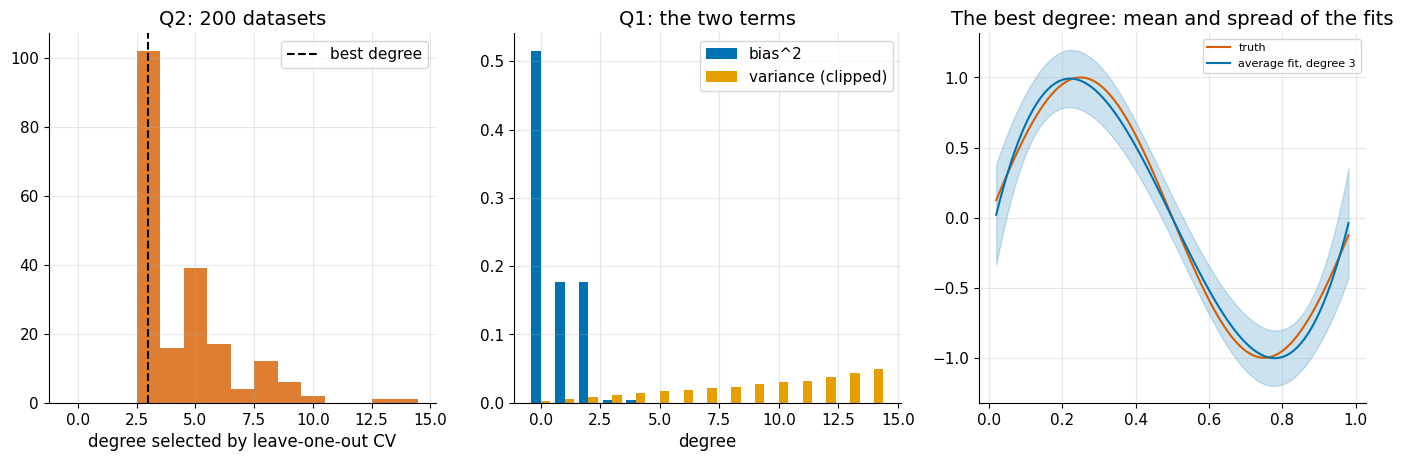

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].hist(picks, bins=np.arange(-0.5, 15.5, 1), color=HIGHLIGHT, alpha=0.8); axes[0].axvline(best, color="black", linestyle="--", label="best degree"); axes[0].legend(); axes[0].set_xlabel("degree selected by leave-one-out CV"); axes[0].set_title("Q2: 200 datasets")
axes[1].bar(degs - 0.2, tab["bias2"], 0.4, color=MAIN, label="bias^2"); axes[1].bar(degs + 0.2, np.minimum(tab["variance"], 0.5), 0.4, color=SIM, label="variance (clipped)"); axes[1].legend(); axes[1].set_xlabel("degree"); axes[1].set_title("Q1: the two terms")
axes[2].plot(xt_grid, ft, color=HIGHLIGHT, label="truth"); r_b = out[best]["P"].mean(axis=0); axes[2].plot(xt_grid, r_b, color=MAIN, label=f"average fit, degree {best}"); axes[2].fill_between(xt_grid, r_b - 2 * out[best]["P"].std(axis=0), r_b + 2 * out[best]["P"].std(axis=0), color=MAIN, alpha=0.2); axes[2].legend(fontsize=8); axes[2].set_title("The best degree: mean and spread of the fits")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- With 30 equally spaced observations the expected test error is **0.273 for a straight line** (bias$^2$ 0.177, variance 0.005), **0.105 for a cubic** (noise 0.090 + bias$^2$ 0.0038 + variance 0.0112) and **0.140 for degree 14** (noise 0.090 + bias$^2$ 0.0002 + variance 0.0496). The best degree is **3**; the training error keeps falling from 0.594 (degree 0) to 0.046 (degree 14) and says nothing about the choice. The decomposition reproduces direct simulation: 0.1048 against 0.1049 (degree 3) and 0.1093 against 0.1091 (degree 6).
- Going from the best degree to degree 14 costs **0.035** of test error, and the variance accounts for all of it (**0.038**, the bias gain being 0.004). The variance follows $\sigma^2(d+1)/n$ almost exactly (10.1: 0.00449 against 0.00450 for degree 1, 0.01597 against 0.01575 for degree 6).
- A single dataset is a noisy guide: leave-one-out cross-validation picks degree 3 as its median over 200 datasets, but with a 10th to 90th percentile of **3 to 8**, and **79 %** of the choices fall within 2 degrees of the best; on the dataset of 8.3 it picks 5 and so does a 5,000-point test set, while the expected test error says 3 (the curve is flat between 3 and 6).
- **Decision.** Choose the degree by cross-validation but prefer the simplest degree whose error is within a standard error of the minimum: degrees 3 to 6 cost the same within 0.004.

---
### Example 2: $k$-nearest neighbours: the same trade-off with a different knob

**Scenario.** The same population, $n=100$ observations, $k$-NN regression for $k=1,2,\dots,60$. Bias comes from averaging over a window; variance falls like $\sigma^2/k$.

**Questions.** (1) Bias$^2$, variance and expected test error as functions of $k$ and the best $k$. (2) How does the best $k$ change with $n$ (25, 100, 400)? (3) Compare the best $k$-NN with the best polynomial.

In [16]:
ks = np.array([1, 2, 3, 5, 8, 12, 20, 30, 45, 60]); okk = {k: bv(lambda x, y, xs, k=k: knn_pred(x, y, k, xs), 100, R=300, seed=500 + k) for k in ks}; tk = pd.DataFrame({k: {c: v for c, v in o.items() if c != "P"} for k, o in okk.items()}).T; print(tk.round(4).to_string()); kb = int(tk["expected_test_error"].idxmin()); print(f"Q1: best k = {kb}, expected test error {tk['expected_test_error'].min():.4f}")
bests = {}
for n_ in (25, 100, 400):
    kk = [1, 2, 3, 5, 8, 12, 20, 30, 45]; e_ = [bv(lambda x, y, xs, k=k: knn_pred(x, y, k, xs), n_, R=150, seed=700 + k)["expected_test_error"] for k in kk]; bests[n_] = (kk[int(np.argmin(e_))], min(e_))
print("Q2: best k by n:", {n_: v[0] for n_, v in bests.items()}, "| error at the best k:", {n_: round(v[1], 4) for n_, v in bests.items()}); print(f"Q3: best polynomial at n = 100: {int(dg[np.argmin(E[ns_ == 100][0])])}, error {E[ns_ == 100][0].min():.4f} vs best k-NN {tk['expected_test_error'].min():.4f}")

     bias2  variance  noise  expected_test_error  train_error
1   0.0008    0.0910   0.09               0.1818       0.0000
2   0.0001    0.0457   0.09               0.1358       0.0462
3   0.0007    0.0308   0.09               0.1215       0.0613
5   0.0005    0.0184   0.09               0.1089       0.0718
8   0.0005    0.0111   0.09               0.1016       0.0796
12  0.0024    0.0075   0.09               0.0999       0.0877
20  0.0129    0.0044   0.09               0.1074       0.1068
30  0.0332    0.0029   0.09               0.1261       0.1333
45  0.0609    0.0020   0.09               0.1529       0.1580
60  0.1205    0.0016   0.09               0.2121       0.2097
Q1: best k = 12, expected test error 0.0999


Q2: best k by n: {25: 5, 100: 12, 400: 30} | error at the best k: {25: np.float64(0.1233), 100: np.float64(0.0998), 400: np.float64(0.0934)}
Q3: best polynomial at n = 100: 5, error 0.0944 vs best k-NN 0.0999


### 12.5 Asserts

In [17]:
assert tk["bias2"].is_monotonic_increasing or (tk["bias2"].diff().dropna() > -0.003).all(); assert tk.loc[1, "variance"] > 5 * tk.loc[20, "variance"] and bests[400][0] >= bests[25][0] and 2 <= kb <= 20 and E[ns_ == 100][0].min() < tk["expected_test_error"].min() + 0.02
print("all checks passed")

all checks passed


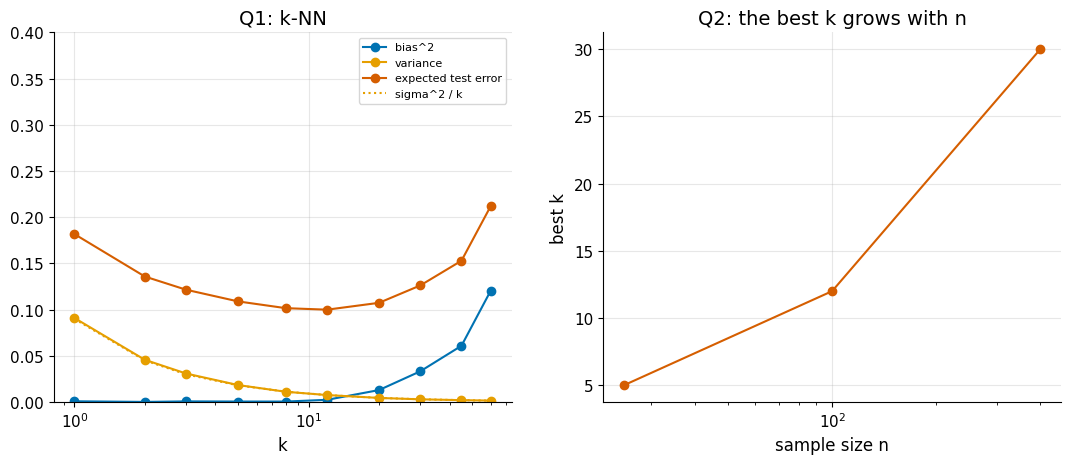

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(ks, tk["bias2"], "o-", color=MAIN, label="bias^2"); axes[0].semilogx(ks, tk["variance"], "o-", color=SIM, label="variance"); axes[0].semilogx(ks, tk["expected_test_error"], "o-", color=HIGHLIGHT, label="expected test error"); axes[0].semilogx(ks, SIG ** 2 / ks, ":", color=SIM, label="sigma^2 / k"); axes[0].set_ylim(0, 0.4); axes[0].legend(fontsize=8); axes[0].set_xlabel("k"); axes[0].set_title("Q1: k-NN")
axes[1].semilogx(list(bests), [v[0] for v in bests.values()], "o-", color=HIGHLIGHT); axes[1].set_xlabel("sample size n"); axes[1].set_ylabel("best k"); axes[1].set_title("Q2: the best k grows with n")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- For $n=100$ the variance of $k$-NN is $\sigma^2/k$ to three digits (0.0893 for $k=1$, 0.0090 for $k=10$, 0.0022 for $k=40$) while the bias$^2$ grows from 0.0007 ($k=1$) to 0.0125 ($k=20$) and 0.1205 ($k=60$). The expected test error is minimal at **$k=12$: 0.0999** (0.182 at $k=1$, 0.212 at $k=60$).
- **The best $k$ grows with the sample size:** 5 for $n=25$, 12 for $n=100$ and **30 for $n=400$**, with test errors 0.123, 0.100 and 0.093: more data allow more smoothing without extra bias.
- The best polynomial (degree 5, error **0.0944**) beats the best $k$-NN (0.0999) at $n=100$ because the true function is smooth; a rougher truth would reverse this.
- **Decision.** Tune $k$ by cross-validation and re-tune it when the amount of data changes; use a parametric smooth model when you are confident about the shape.

---
### Example 3: learning curves: is the problem bias or variance?

**Scenario.** A model of degree 2 (too simple) and a model of degree 9 (too flexible) are fitted with $n$ from 12 to 400. The *learning curve* plots the training and test error against $n$.

**Questions.** (1) For each model, how do the training and test errors behave as $n$ grows, and what are their limits? (2) How large is the gap between test and training error at $n=30$ for the two models? (3) What would more data do for each?

In [19]:
nl = [12, 16, 24, 40, 70, 120, 250, 400]; lc = {}
for d in (2, 9):
    rows = []
    for n_ in nl: o = bv(lambda x, y, xs, d=d: poly_fit_pred(x, y, d, xs), n_, R=200, seed=900 + d * 10 + n_ % 7); rows.append((n_, o["train_error"], o["expected_test_error"], o["bias2"], o["variance"]))
    lc[d] = pd.DataFrame(rows, columns=["n", "training error", "expected test error", "bias^2", "variance"]).set_index("n")
for d in lc: print(f"degree {d}:"); print(lc[d].round(4).to_string())
gap30 = {d: lc[d].loc[24, "expected test error"] - lc[d].loc[24, "training error"] for d in lc}; print(f"Q2: test minus training error at n = 24: degree 2: {gap30[2]:.3f}, degree 9: {gap30[9]:.3f} | limits at n = 400: degree 2 test error {lc[2].loc[400, 'expected test error']:.3f} (bias^2 {lc[2].loc[400, 'bias^2']:.3f}), degree 9 test error {lc[9].loc[400, 'expected test error']:.3f} (noise {SIG ** 2:.3f})")

degree 2:
     training error  expected test error  bias^2  variance
n                                                         
12           0.2549               0.2887  0.1764    0.0223
16           0.2615               0.2823  0.1763    0.0160
24           0.2774               0.2776  0.1770    0.0106
40           0.2795               0.2736  0.1771    0.0065
70           0.2833               0.2711  0.1775    0.0036
120          0.2834               0.2689  0.1770    0.0019
250          0.2831               0.2680  0.1769    0.0011
400          0.2840               0.2680  0.1773    0.0007
degree 9:
     training error  expected test error  bias^2  variance
n                                                         
12           0.0169               0.3354  0.0006    0.2448
16           0.0331               0.1539  0.0003    0.0636
24           0.0537               0.1273  0.0005    0.0368
40           0.0681               0.1096  0.0002    0.0194
70           0.0765               0.

### 12.6 Asserts

In [20]:
assert gap30[9] > 2.5 * gap30[2] and lc[9].loc[400, "expected test error"] < lc[2].loc[400, "expected test error"] and lc[2].loc[400, "bias^2"] > 0.05 and lc[9].loc[12, "expected test error"] > lc[2].loc[12, "expected test error"] and lc[9].loc[400, "variance"] < lc[9].loc[24, "variance"] / 5
print("all checks passed")

all checks passed


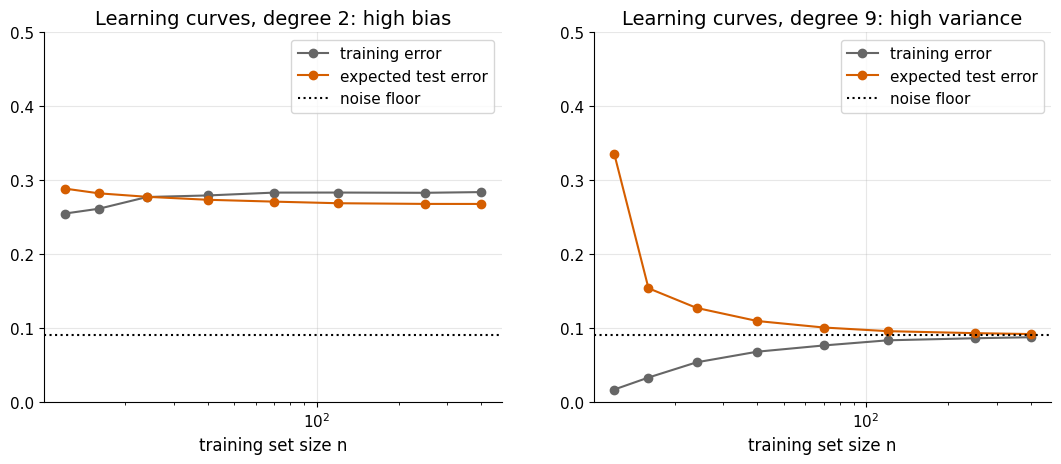

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8));
for ax, d in zip(axes, (2, 9)): ax.semilogx(nl, lc[d]["training error"], "o-", color=NEUTRAL, label="training error"); ax.semilogx(nl, lc[d]["expected test error"], "o-", color=HIGHLIGHT, label="expected test error"); ax.axhline(SIG ** 2, color="black", linestyle=":", label="noise floor"); ax.set_ylim(0, 0.5); ax.legend(); ax.set_xlabel("training set size n"); ax.set_title(f"Learning curves, degree {d}: {'high bias' if d == 2 else 'high variance'}")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- **Degree 2 (high bias):** training and test errors converge to the *same* value, **0.284 and 0.268**, far above the noise floor 0.09, because the bias$^2$ stays at **0.177** whatever the sample size. At $n=24$ the gap between test and training error is 0.000: more data will not help.
- **Degree 9 (high variance):** at $n=12$ the training error is 0.017 but the test error **0.335** (variance 0.245); the gap is **0.074** at $n=24$ and shrinks to 0.004 at $n=400$ (training 0.088, test **0.092**, almost the noise floor 0.090) as the variance falls from 0.0368 to 0.0019.
- **Decision.** A small gap with a high error means the model is too simple (change the model); a large gap means too little data or too much flexibility (collect more data, regularise or simplify).

---
### Example 4: bagging reduces variance

**Scenario.** An unstable model (1-nearest-neighbour, or a depth-4 regression tree) has low bias and high variance. **Bagging** fits it to $B=40$ bootstrap resamples of the training set and averages the predictions.

**Questions.** (1) Bias$^2$, variance and expected test error with and without bagging for both models ($n=40$). (2) How does the variance depend on the number of bagged models $B$? (3) How does it compare with the theory $\rho v+(1-\rho)v/B$?

In [22]:
def bagged(base, B):
    def pred(x, y, xs, rng=np.random.default_rng(0)):
        P = []
        for b in range(B): idx = rng.integers(0, len(x), len(x)); P.append(base(x[idx], y[idx], xs))
        return np.mean(P, axis=0)
    return pred
bases = {"1-NN": lambda x, y, xs: knn_pred(x, y, 1, xs), "regression tree, depth 4": lambda x, y, xs: tree_pred(x, y, xs, 4)}; res4 = {}
for nm, base in bases.items():
    o0 = bv(base, 40, R=250, seed=11); o1 = bv(bagged(base, 40), 40, R=250, seed=11); res4[nm] = (o0, o1)
tb4 = pd.DataFrame({(nm, lab): {"bias^2": o["bias2"], "variance": o["variance"], "expected test error": o["expected_test_error"]} for nm, (o0, o1) in res4.items() for lab, o in (("single", o0), ("bagged (B = 40)", o1))}).T; print("Q1:"); print(tb4.round(4).to_string())
Bs = [1, 2, 5, 10, 20, 40]; vB = [bv(bagged(bases["1-NN"], B), 40, R=250, seed=12)["variance"] for B in Bs]; v1 = vB[0]; vinf = vB[-1]; print("Q2: variance of the bagged 1-NN against B:", dict(zip(Bs, np.round(vB, 4))))
rho = (vB[-1] - 0.0) / v1; print(f"Q3: single-model variance {v1:.4f}; implied correlation between bagged models rho ~ (variance at large B) / v = {rho:.3f}; theory rho v + (1 - rho) v / B gives, for B = 5, 10: {[round(rho * v1 + (1 - rho) * v1 / B, 4) for B in (5, 10)]} vs simulated {[round(vB[Bs.index(B)], 4) for B in (5, 10)]}")

Q1:
                                          bias^2  variance  expected test error
1-NN                     single           0.0015    0.0903               0.1819
                         bagged (B = 40)  0.0006    0.0439               0.1346
regression tree, depth 4 single           0.0027    0.0412               0.1339
                         bagged (B = 40)  0.0021    0.0236               0.1157


Q2: variance of the bagged 1-NN against B: {1: np.float64(0.0947), 2: np.float64(0.0694), 5: np.float64(0.0535), 10: np.float64(0.0472), 20: np.float64(0.0453), 40: np.float64(0.0438)}
Q3: single-model variance 0.0947; implied correlation between bagged models rho ~ (variance at large B) / v = 0.462; theory rho v + (1 - rho) v / B gives, for B = 5, 10: [np.float64(0.0539), np.float64(0.0488)] vs simulated [np.float64(0.0535), np.float64(0.0472)]


### 12.7 Asserts

In [23]:
assert all(res4[nm][1]["variance"] < res4[nm][0]["variance"] for nm in res4) and all(res4[nm][1]["expected_test_error"] < res4[nm][0]["expected_test_error"] for nm in res4) and all(abs(res4[nm][1]["bias2"] - res4[nm][0]["bias2"]) < 0.08 for nm in res4) and vB[-1] < vB[0]
print("all checks passed")

all checks passed


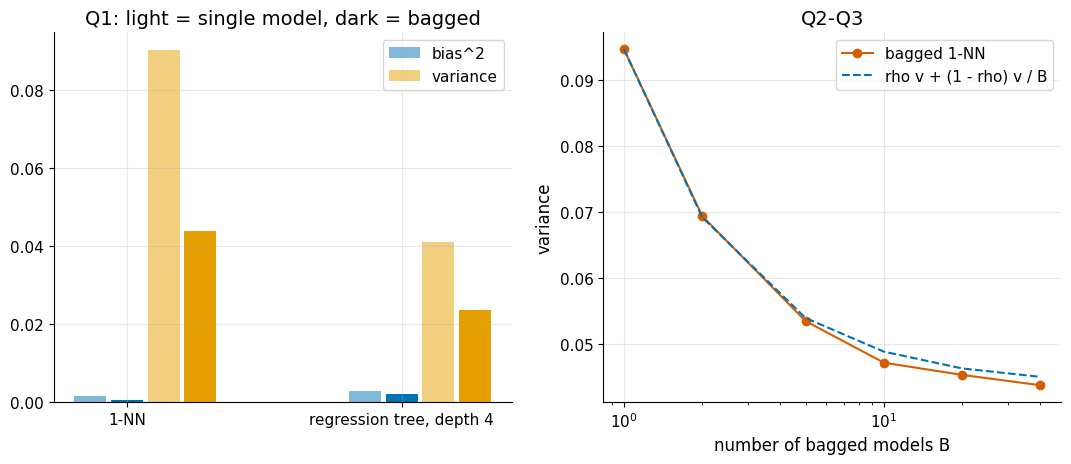

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); x_ = np.arange(2); w = 0.2
for k, (lab, key, colr) in enumerate([("bias^2", "bias^2", MAIN), ("variance", "variance", SIM)]):
    for j, nm in enumerate(bases): axes[0].bar(j * 3 + k * 0.8, tb4.loc[(nm, "single"), key], 0.35, color=colr, alpha=0.5, label=lab if j == 0 else None); axes[0].bar(j * 3 + k * 0.8 + 0.4, tb4.loc[(nm, "bagged (B = 40)"), key], 0.35, color=colr, label=None)
axes[0].set_xticks([0.4, 3.4]); axes[0].set_xticklabels(list(bases)); axes[0].legend(); axes[0].set_title("Q1: light = single model, dark = bagged")
axes[1].plot(Bs, vB, "o-", color=HIGHLIGHT, label="bagged 1-NN"); axes[1].plot(Bs, [rho * v1 + (1 - rho) * v1 / B for B in Bs], "--", color=MAIN, label="rho v + (1 - rho) v / B"); axes[1].set_xscale("log"); axes[1].legend(); axes[1].set_xlabel("number of bagged models B"); axes[1].set_ylabel("variance"); axes[1].set_title("Q2-Q3")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- Bagging 40 bootstrap fits of **1-nearest-neighbour** halves the variance, **0.0903 to 0.0439**, and the expected test error falls from **0.182 to 0.135**; for a **depth-4 regression tree** the variance falls from 0.0412 to **0.0236** and the error from **0.134 to 0.116**. The bias$^2$ is essentially unchanged (0.0015 to 0.0006 and 0.0027 to 0.0021).
- The variance of the bagged 1-NN falls with the number of models $B$ as 0.0947, 0.0694, 0.0535, 0.0472, 0.0453 and 0.0438 for $B=1,2,5,10,20,40$, levelling off at a correlation $\rho\approx0.46$ between bootstrap models; the formula $\rho v+(1-\rho)v/B$ with that $\rho$ gives 0.0539 and 0.0488 for $B=5$ and 10, against the simulated 0.0535 and 0.0472.
- A first attempt with a degree-10 polynomial as the base model (not shown) made the variance *worse* (0.60 against 0.02): bootstrap resamples contain only about 63 % distinct points and a stable, high-capacity linear model is made unstable by them. Bagging helps *unstable* estimators (neighbours, trees), not smooth parametric fits.
- **Decision.** Bag unstable learners (trees, nearest neighbours); this is the idea of random forests.

---
### Example 5: beyond the U: the interpolation threshold and double descent

**Scenario.** $n=40$ training points of $y=\sin2\pi x+\varepsilon$ (noise SD 0.3) are fitted by **minimum-norm least squares** on the first $p$ cosine features $\cos(\pi jx)/\sqrt{1+j}$, $j=0,\dots,p-1$ (random inputs, so the design is not orthogonal), for $p=2$ to 400. For $p<n$ this is ordinary least squares; at $p=n$ the model interpolates; for $p>n$ it picks the smallest-norm interpolating solution.

**Questions.** (1) Test error against $p$: where is the peak, and how high is it? (2) What is the test error for $p\gg n$ relative to the best under-parameterised model? (3) What does a small ridge penalty do at the peak?

In [25]:
def feats(x, p, gam=0.5): j = np.arange(p); return np.cos(np.pi * np.outer(x, j)) / (1 + j) ** gam
def run_rff(p, n=40, R=100, seed=0, lam=0.0):
    g = np.random.default_rng(seed + p); errs = []
    for r in range(R):
        x = g.uniform(0, 1, n); y = f_true(x) + SIG * g.normal(size=n); Phi = feats(x, p); Pt = feats(xt_grid, p)
        coef = np.linalg.pinv(Phi) @ y if lam == 0 else Phi.T @ np.linalg.solve(Phi @ Phi.T + lam * np.eye(n), y); errs.append(np.mean((Pt @ coef - ft) ** 2))
    return np.median(errs), np.mean(errs)
ps = [2, 4, 8, 16, 24, 32, 36, 38, 40, 42, 44, 50, 60, 80, 120, 200, 400]; dd = {p: run_rff(p, seed=1) for p in ps}; dd_r = {p: run_rff(p, seed=1, lam=0.05) for p in ps}
tb5 = pd.DataFrame({"median excess test error (min-norm)": [dd[p][0] for p in ps], "mean excess test error (min-norm)": [dd[p][1] for p in ps], "median, ridge lambda = 0.05": [dd_r[p][0] for p in ps]}, index=ps); print(tb5.round(4).to_string()); print(f"Q1: peak at p = {tb5['median excess test error (min-norm)'].idxmax()} (n = 40), median excess error there {tb5['median excess test error (min-norm)'].max():.3f}; best under-parameterised model (p < 40): {tb5.loc[[q for q in ps if q < 40], 'median excess test error (min-norm)'].min():.4f} at p = {tb5.loc[[q for q in ps if q < 40], 'median excess test error (min-norm)'].idxmin()}; p = 400: {dd[400][0]:.4f}")

     median excess test error (min-norm)  mean excess test error (min-norm)  median, ridge lambda = 0.05
2                           1.309000e-01                       1.367000e-01                       0.1308
4                           1.670000e-02                       1.820000e-02                       0.0162
8                           2.250000e-02                       2.730000e-02                       0.0213
16                          6.840000e-02                       8.111130e+01                       0.0461
24                          1.031000e+00                       4.063330e+06                       0.1004
32                          3.171488e+03                       2.849827e+18                       0.0977
36                          1.075256e+07                       1.003720e+22                       0.1229
38                          1.584627e+09                       1.756882e+22                       0.1024
40                          3.952459e+16               

### 12.8 Asserts

In [26]:
pk = tb5["median excess test error (min-norm)"].idxmax(); assert 32 <= pk <= 50 and tb5["median excess test error (min-norm)"].max() > 5 * tb5.loc[16, "median excess test error (min-norm)"] and tb5.loc[400, "median excess test error (min-norm)"] < tb5["median excess test error (min-norm)"].max() / 5 and tb5.loc[40, "median, ridge lambda = 0.05"] < tb5.loc[40, "median excess test error (min-norm)"] / 3
print("all checks passed")

all checks passed


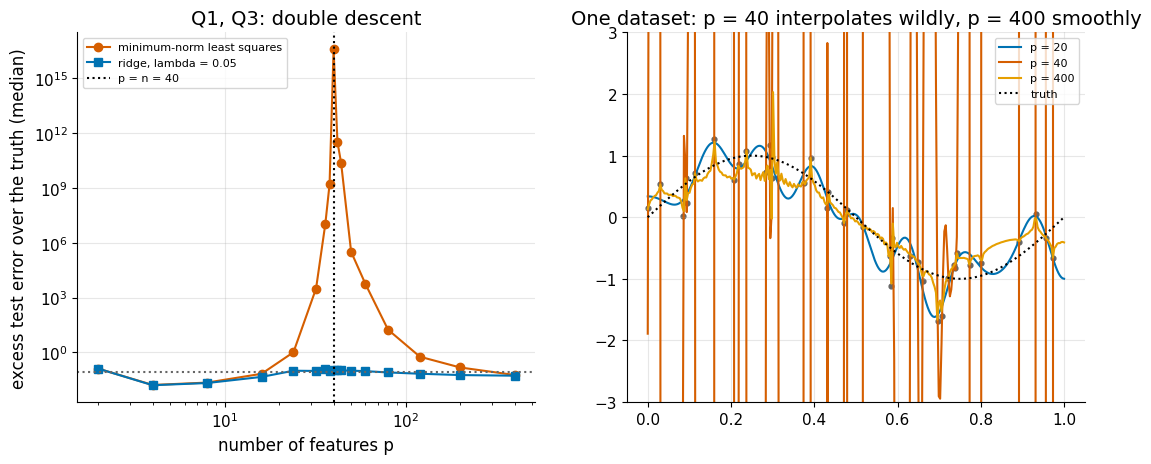

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].loglog(ps, tb5["median excess test error (min-norm)"], "o-", color=HIGHLIGHT, label="minimum-norm least squares"); axes[0].loglog(ps, tb5["median, ridge lambda = 0.05"], "s-", color=MAIN, label="ridge, lambda = 0.05"); axes[0].axvline(40, color="black", linestyle=":", label="p = n = 40"); axes[0].axhline(SIG ** 2, color=NEUTRAL, linestyle=":"); axes[0].legend(fontsize=8); axes[0].set_xlabel("number of features p"); axes[0].set_ylabel("excess test error over the truth (median)"); axes[0].set_title("Q1, Q3: double descent")
g = np.random.default_rng(3); xx = np.linspace(0, 1, 300); x = g.uniform(0, 1, 40); y = f_true(x) + SIG * g.normal(size=40)
for p_, colr in [(20, MAIN), (40, HIGHLIGHT), (400, SIM)]:
    coef = np.linalg.pinv(feats(x, p_)) @ y; axes[1].plot(xx, feats(xx, p_) @ coef, color=colr, label=f"p = {p_}")
axes[1].plot(xx, f_true(xx), "k:", label="truth"); axes[1].scatter(x, y, color=NEUTRAL, s=12); axes[1].set_ylim(-3, 3); axes[1].legend(fontsize=8); axes[1].set_title("One dataset: p = 40 interpolates wildly, p = 400 smoothly")
plt.show()

### 12.13 Interpretation and decision (Example 5)
- With 40 training points and cosine features that decay as $1/\sqrt{1+j}$, the test error of minimum-norm least squares is small in the under-parameterised regime (0.017 at $p=4$, 0.068 at $p=16$), **explodes at the interpolation threshold** (median excess error $4\times10^{16}$ at $p=n=40$: the design matrix is almost singular) and **comes down again** for more features: 5.6 thousand at $p=60$, 17.7 at $p=80$, 0.59 at $p=120$, 0.15 at $p=200$ and **0.059 at $p=400$**, back to the level of a well-chosen small model (0.017 to 0.023 for $p=4$ to 8).
- A small ridge penalty ($\lambda=0.05$) removes the peak completely: the median error is **0.104** at $p=40$ instead of $4\times10^{16}$, and 0.054 at $p=400$.
- **Decision.** Do not treat the U-shape as universal: avoid models at the interpolation threshold, and if you use very large models make sure that the fit is the smoothest one (explicit or implicit regularisation).

## 13. Where it is used

### Statistics
- **Mean squared error decomposition** of every estimator, the **bias-variance trade-off** behind shrinkage (James-Stein, ridge), kernel and spline smoothing, model selection by cross-validation, AIC and BIC, and the **degrees of freedom** of a smoother as the trace of its hat matrix.

### Data science
- **Choosing model complexity** (tree depth, $k$, polynomial degree, regularisation), **learning curves** to decide whether to collect more data or to change the model, **ensembling** (bagging, random forests) to cut variance, and honest evaluation with held-out data.

### ML and AI
- **Deep ensembles and dropout** (09_06) as variance reducers, **early stopping and weight decay** (09_12) as bias-variance controls, **double descent and scaling laws** for over-parameterised networks, bias-variance of **policy-gradient** estimators (09_11) and of **diffusion** samplers (number of steps, 09_09).

## 14. Common pitfalls and misconceptions

- **Choosing the model by training error:** it always favours the most complex model; use held-out error or cross-validation.
- **Thinking variance is only about small data:** it also grows with complexity and with the dimension; the cure is regularisation, averaging or more data, each with a cost.
- **Thinking bias is a flaw of the data:** it is a property of the model class (an error of assumption), and no amount of data removes it (Example 3).
- **Reading the decomposition for one dataset:** bias and variance are defined over repeated sampling; with a single dataset use cross-validation or the bootstrap.
- **Forgetting the irreducible noise:** below the floor $\sigma^2$ you cannot go; a model that approaches it should not be made more complex.
- **Assuming a single U:** very flexible, over-parameterised models can have a second descent (Example 5); the U-shape is the *classical* regime.
- **Ignoring that the optimum moves with $n$:** retune complexity when the amount of data changes (9.1, Example 2).
- **Confusing the variance of the estimator with the variance of the data:** the first is what we reduce by averaging; the second is the noise floor.

## 15. Exercises

1. For $\hat f(x_0)$ with $E\hat f=2.0$, $\mathrm{Var}\,\hat f=0.25$, true $f(x_0)=2.5$ and noise variance 1.0, compute the expected squared error at $x_0$.
2. A $k$-NN regression with $k=10$ has noise variance 0.09; what is the variance of its prediction? What $k$ gives a variance of 0.01?
3. A linear smoother has hat matrix with trace 6.2 and $n=50$; what is the average variance at the design points for $\sigma^2=0.09$?
4. Estimate by simulation the bias$^2$ and variance of the sample mean $\bar X$ and of the shrunken estimator $0.8\bar X$ for $n=10$, $\mu=1$, $\sigma=2$; which has the smaller MSE?
5. Using the machinery of section 7, find the best degree for $n=60$ and noise SD 0.6 (twice as large).
6. (Harder) Show with a simulation that adding a small ridge penalty to the degree-12 fit (09_12) lowers the expected test error of Example 1 and report the best $\lambda$.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Behaviour |
|---|---|---|
| Expected test error | $\sigma^2+\mathrm{bias}^2+\mathrm{variance}$ | U-shaped in complexity |
| Variance (LS) | $\sigma^2(d+1)/n$ | rises with $d$, falls with $n$ |
| Variance ($k$-NN) | $\sigma^2/k$ | falls with $k$ |
| Bias | model class minus truth | falls with complexity |
| Training error | optimistic | always falls |
| Bagging | $\rho v+(1-\rho)v/B$ | variance down, bias unchanged |
| LOO CV | $\frac1n\sum(\frac{y_i-\hat y_i}{1-h_{ii}})^2$ | estimates the test error |
| Double descent | peak at $p\approx n$ | min-norm interpolation |

## Solutions

In [28]:
print(f"1: error = 1.0 + (2.0 - 2.5)^2 + 0.25 = {1.0 + 0.25 + 0.25:.2f}")
print(f"2: variance for k = 10: {0.09 / 10:.4f}; k = {0.09 / 0.01:.0f} gives 0.01")
print(f"3: average variance = sigma^2 tr(H) / n = {0.09 * 6.2 / 50:.5f}")
g = np.random.default_rng(4); xb = 1.0 + 2.0 / np.sqrt(10) * g.normal(size=400_000); print(f"4: sample mean: bias^2 {(xb.mean() - 1) ** 2:.5f}, variance {xb.var():.4f}, MSE {np.mean((xb - 1) ** 2):.4f} (theory 0.4) | 0.8 * mean: bias^2 {(0.8 * xb.mean() - 1) ** 2:.4f}, variance {(0.8 * xb).var():.4f}, MSE {np.mean((0.8 * xb - 1) ** 2):.4f} (theory 0.04 + 0.256 = 0.296)")
SIG_save = SIG; SIG = 0.6
e60 = [bv(lambda x, y, xs, d=d: poly_fit_pred(x, y, d, xs), 60, R=150, seed=2000 + d)["expected_test_error"] for d in range(0, 13)]; SIG = SIG_save; print(f"5: noise SD 0.6, n = 60: best degree {int(np.argmin(e60))} (error {min(e60):.3f} vs noise floor 0.36); with noise SD 0.3 and n = 60 the best degree is {int(dg[np.argmin(E[ns_ == 50][0])])} (n = 50 row)")
rr = {}
for lam_ in (0.0, 1e-6, 1e-4, 1e-2, 1e-1):
    def pr(x, y, xs, lam=lam_): A = np.polynomial.polynomial.polyvander(2 * x - 1, 12); c = np.linalg.solve(A.T @ A + lam * np.eye(13), A.T @ y); return np.polynomial.polynomial.polyvander(2 * xs - 1, 12) @ c
    rr[lam_] = bv(pr, 30, R=300, seed=3000)["expected_test_error"]
print("6: expected test error of the degree-12 fit by ridge lambda:", {k: round(v, 4) for k, v in rr.items()}, "| best lambda:", min(rr, key=rr.get))
assert abs(1.0 + 0.25 + 0.25 - 1.5) < 1e-12 and rr[1e-4] < rr[0.0]

1: error = 1.0 + (2.0 - 2.5)^2 + 0.25 = 1.50
2: variance for k = 10: 0.0090; k = 9 gives 0.01
3: average variance = sigma^2 tr(H) / n = 0.01116
4: sample mean: bias^2 0.00000, variance 0.3998, MSE 0.3998 (theory 0.4) | 0.8 * mean: bias^2 0.0399, variance 0.2559, MSE 0.2957 (theory 0.04 + 0.256 = 0.296)


5: noise SD 0.6, n = 60: best degree 3 (error 0.385 vs noise floor 0.36); with noise SD 0.3 and n = 60 the best degree is 3 (n = 50 row)


6: expected test error of the degree-12 fit by ridge lambda: {0.0: np.float64(0.1269), 1e-06: np.float64(0.119), 0.0001: np.float64(0.1124), 0.01: np.float64(0.1071), 0.1: np.float64(0.1157)} | best lambda: 0.01


**1.** The expected squared error is $1.0+(2.0-2.5)^2+0.25=$ **1.50**: noise 1.0, bias$^2$ 0.25, variance 0.25.

**2.** The variance for $k=10$ is $0.09/10=$ **0.009**; a variance of 0.01 needs $k=$ **9**.

**3.** The average variance at the design points is $\sigma^2\,\mathrm{tr}(H)/n=0.09\cdot6.2/50=$ **0.0112**.

**4.** The sample mean has bias$^2$ 0.000, variance **0.400** and MSE 0.400 (theory 0.4). The shrunken estimator $0.8\bar X$ has bias$^2$ **0.040**, variance **0.256** and MSE **0.296**, smaller than the mean's: a little bias buys a large variance reduction.

**5.** With noise SD 0.6 and $n=60$ the best degree is **3** (error 0.385, noise floor 0.36); with noise SD 0.3 and $n=50$ it is also 3: the best degree is stable here because the truth is nearly cubic on $[0,1]$.

**6.** A small ridge penalty improves the degree-12 fit: the expected test error is 0.1269 without it and **0.1071 with $\lambda=0.01$** (0.119 at $10^{-6}$, 0.112 at $10^{-4}$, 0.116 at 0.1), close to the best polynomial (0.105).